###1. Import Libraries and set up all prerequitise

In [2]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier
import optuna

RANDOM_STATE = 42
CV_FOLDS = 5
OPTUNA_TRIALS = 30

###2. Load Dataset

In [4]:
df = pd.read_csv("heart.csv")
print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumns:", df.columns.tolist())

Dataset shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


\nColumns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


###3. Detect Target Column

In [5]:
possible_targets = ["target", "Target", "HeartDisease", "heart_disease", "output", "Outcome", "condition"]
TARGET_COLUMN = next((c for c in possible_targets if c in df.columns), df.columns[-1])
print("Selected target column:", TARGET_COLUMN)

X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

Selected target column: target


###4. Preprocessing steps

In [6]:
X = pd.get_dummies(X, drop_first=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (820, 13) Test: (205, 13)


###5. Define Model

In [7]:
models = {
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="logloss",
        verbosity=0,
        n_jobs=1
    )
}

###6. Grid search spaces (pipeline parameter names use model_prefix)

In [8]:
param_grids = {
    "GradientBoosting": {
        "model__n_estimators": [100, 150, 200],
        "model__learning_rate": [0.05, 0.1, 0.2],
        "model__max_depth": [2, 3, 4],
        "model__subsample": [0.8, 1.0]
    },
    "XGBoost": {
        "model__n_estimators": [100, 150, 200],
        "model__learning_rate": [0.03, 0.1, 0.2],
        "model__max_depth": [3, 4, 5],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0]
    }
}

###7. Randomized search draws from these finite lists

In [9]:
random_spaces = param_grids

###8. Run Default, GridSearchCV, RandomizedSearchCV and Optuna

Each method is evaluated with the same CV setup and held-out test set. Runtime measures the complete fitting/evaluation process for that method (CV search time for search methods). Optuna optimizes CV accuracy.

In [11]:
results = []
best_estimators = {}

def make_pipeline(estimator):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])

for model_name, base_model in models.items():
    print(f"\n===== {model_name} =====")

    # 1) Default parameters
    pipeline = make_pipeline(base_model)
    start = time.perf_counter()
    default_cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    pipeline.fit(X_train, y_train)
    default_test = accuracy_score(y_test, pipeline.predict(X_test))
    default_time = time.perf_counter() - start
    results.append({
        "Model": model_name, "Method": "Default",
        "CV Accuracy": default_cv_scores.mean(),
        "Test Accuracy": default_test, "Runtime (s)": default_time
    })
    best_estimators[(model_name, "Default")] = pipeline

    # 2) GridSearchCV
    grid = GridSearchCV(
        make_pipeline(base_model), param_grids[model_name],
        cv=cv, scoring="accuracy", n_jobs=-1, refit=True
    )
    start = time.perf_counter()
    grid.fit(X_train, y_train)
    grid_time = time.perf_counter() - start
    grid_test = accuracy_score(y_test, grid.predict(X_test))
    results.append({
        "Model": model_name, "Method": "GridSearchCV",
        "CV Accuracy": grid.best_score_,
        "Test Accuracy": grid_test, "Runtime (s)": grid_time
    })
    best_estimators[(model_name, "GridSearchCV")] = grid.best_estimator_
    print("Grid best params:", grid.best_params_)

    # 3) RandomizedSearchCV
    random_search = RandomizedSearchCV(
        make_pipeline(base_model), random_spaces[model_name],
        n_iter=20, cv=cv, scoring="accuracy", n_jobs=-1,
        random_state=RANDOM_STATE, refit=True
    )
    start = time.perf_counter()
    random_search.fit(X_train, y_train)
    random_time = time.perf_counter() - start
    random_test = accuracy_score(y_test, random_search.predict(X_test))
    results.append({
        "Model": model_name, "Method": "RandomizedSearchCV",
        "CV Accuracy": random_search.best_score_,
        "Test Accuracy": random_test, "Runtime (s)": random_time
    })
    best_estimators[(model_name, "RandomizedSearchCV")] = random_search.best_estimator_
    print("Random best params:", random_search.best_params_)

    # 4) Optuna optimization
    def objective(trial):
        if model_name == "GradientBoosting":
            trial_model = GradientBoostingClassifier(
                n_estimators=trial.suggest_int("n_estimators", 80, 250),
                learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                max_depth=trial.suggest_int("max_depth", 2, 5),
                subsample=trial.suggest_float("subsample", 0.6, 1.0),
                random_state=RANDOM_STATE
            )
        else:
            trial_model = XGBClassifier(
                n_estimators=trial.suggest_int("n_estimators", 80, 250),
                learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                max_depth=trial.suggest_int("max_depth", 2, 6),
                subsample=trial.suggest_float("subsample", 0.6, 1.0),
                colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
                eval_metric="logloss", verbosity=0, n_jobs=1,
                random_state=RANDOM_STATE
            )
        trial_pipeline = make_pipeline(trial_model)
        scores = cross_val_score(trial_pipeline, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
        return scores.mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    start = time.perf_counter()
    study.optimize(objective, n_trials=OPTUNA_TRIALS, show_progress_bar=True)
    optuna_time = time.perf_counter() - start

    # Build/final-fit the best Optuna model and test
    optuna_params = study.best_params
    if model_name == "GradientBoosting":
        optuna_model = GradientBoostingClassifier(**optuna_params, random_state=RANDOM_STATE)
    else:
        optuna_model = XGBClassifier(
            **optuna_params, eval_metric="logloss", verbosity=0, n_jobs=1,
            random_state=RANDOM_STATE
        )
    optuna_pipeline = make_pipeline(optuna_model)
    optuna_pipeline.fit(X_train, y_train)
    optuna_test = accuracy_score(y_test, optuna_pipeline.predict(X_test))
    results.append({
        "Model": model_name, "Method": "Optuna",
        "CV Accuracy": study.best_value,
        "Test Accuracy": optuna_test, "Runtime (s)": optuna_time
    })
    best_estimators[(model_name, "Optuna")] = optuna_pipeline
    print("Optuna best params:", study.best_params)

print("\nAll searches completed.")


===== GradientBoosting =====
Grid best params: {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 200, 'model__subsample': 0.8}


[I 2026-11-21 17:55:12,585] A new study created in memory with name: no-name-fc2391ef-ee16-47bc-bcea-9585ca9f4a80


Random best params: {'model__subsample': 0.8, 'model__n_estimators': 150, 'model__max_depth': 4, 'model__learning_rate': 0.1}


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-21 17:55:14,172] Trial 0 finished with value: 0.9817073170731708 and parameters: {'n_estimators': 144, 'learning_rate': 0.2536999076681772, 'max_depth': 4, 'subsample': 0.8394633936788146}. Best is trial 0 with value: 0.9817073170731708.
[I 2026-11-21 17:55:14,961] Trial 1 finished with value: 0.8548780487804878 and parameters: {'n_estimators': 106, 'learning_rate': 0.01699897838270077, 'max_depth': 2, 'subsample': 0.9464704583099741}. Best is trial 0 with value: 0.9817073170731708.
[I 2026-11-21 17:55:16,199] Trial 2 finished with value: 0.9439024390243903 and parameters: {'n_estimators': 182, 'learning_rate': 0.11114989443094977, 'max_depth': 2, 'subsample': 0.9879639408647978}. Best is trial 0 with value: 0.9817073170731708.
[I 2026-11-21 17:55:17,588] Trial 3 finished with value: 0.8707317073170732 and parameters: {'n_estimators': 222, 'learning_rate': 0.020589728197687916, 'max_depth': 2, 'subsample': 0.6733618039413735}. Best is trial 0 with value: 0.9817073170731708.


[I 2026-11-21 17:56:59,895] A new study created in memory with name: no-name-d5c30738-79c8-401a-b9e9-c7cf0cafd27f


Random best params: {'model__subsample': 0.8, 'model__n_estimators': 150, 'model__max_depth': 4, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-21 17:57:00,318] Trial 0 finished with value: 0.9817073170731707 and parameters: {'n_estimators': 144, 'learning_rate': 0.2536999076681772, 'max_depth': 5, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746}. Best is trial 0 with value: 0.9817073170731707.
[I 2026-11-21 17:57:00,922] Trial 1 finished with value: 0.9548780487804878 and parameters: {'n_estimators': 106, 'learning_rate': 0.012184186502221764, 'max_depth': 6, 'subsample': 0.8404460046972835, 'colsample_bytree': 0.8832290311184181}. Best is trial 0 with value: 0.9817073170731707.
[I 2026-11-21 17:57:01,233] Trial 2 finished with value: 0.9817073170731707 and parameters: {'n_estimators': 83, 'learning_rate': 0.2708160864249968, 'max_depth': 6, 'subsample': 0.6849356442713105, 'colsample_bytree': 0.6727299868828402}. Best is trial 0 with value: 0.9817073170731707.
[I 2026-11-21 17:57:01,647] Trial 3 finished with value: 0.9402439024390243 and parameters: {'n_estimators': 111, 'learning_rate': 0

###9. Comparison Table

In [12]:
comparison = pd.DataFrame(results)
comparison["CV Accuracy"] = comparison["CV Accuracy"].round(4)
comparison["Test Accuracy"] = comparison["Test Accuracy"].round(4)
comparison["Runtime (s)"] = comparison["Runtime (s)"].round(2)

comparison = comparison.sort_values(["Model", "Method"])
display(comparison)

,Model,Method,CV Accuracy,Test Accuracy,Runtime (s)
0,GradientBoosting,Default,0.9634,0.9756,3.98
1,GradientBoosting,GridSearchCV,0.9841,1.0000,71.19
3,GradientBoosting,Optuna,0.9841,1.0000,72.86
2,GradientBoosting,RandomizedSearchCV,0.9841,1.0000,27.15
4,XGBoost,Default,0.9866,1.0000,0.31
5,XGBoost,GridSearchCV,0.9878,1.0000,28.49
7,XGBoost,Optuna,0.9878,1.0000,9.40
6,XGBoost,RandomizedSearchCV,0.9854,1.0000,4.90


###10. Visualize score and runtime

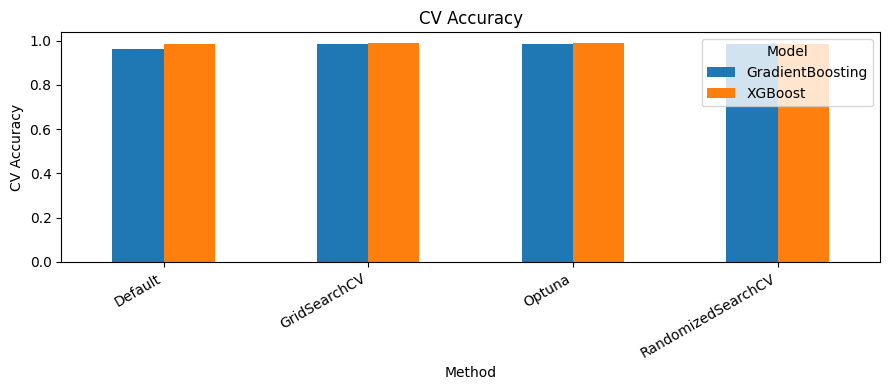

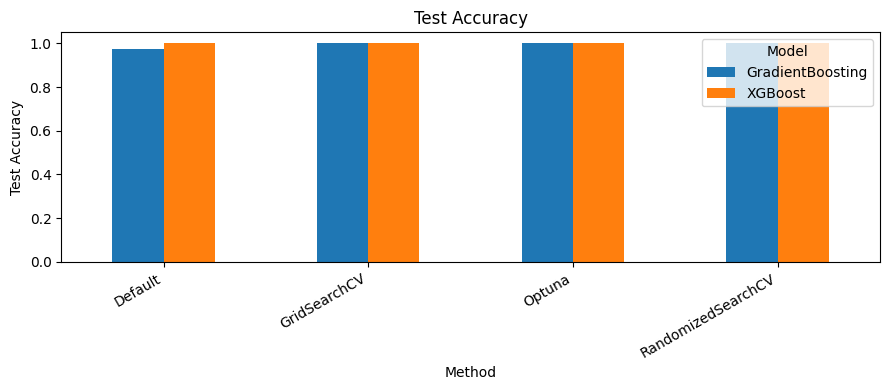

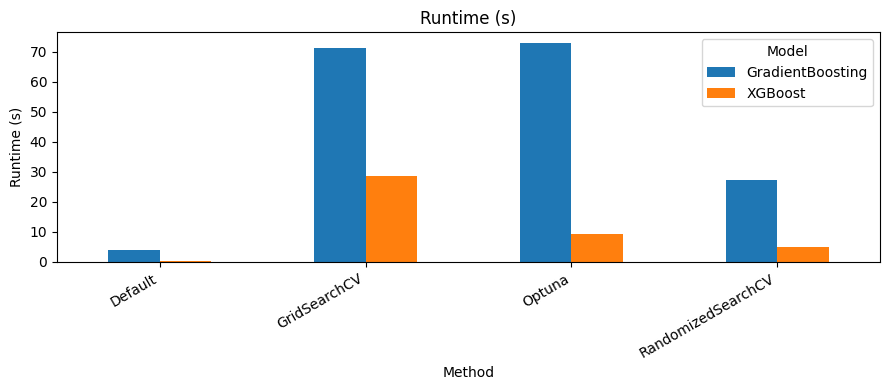

In [14]:
import matplotlib.pyplot as plt

for metric in ["CV Accuracy", "Test Accuracy", "Runtime (s)"]:
    pivot = comparison.pivot(index="Method", columns="Model", values=metric)
    ax = pivot.plot(kind="bar", figsize=(9, 4), title=metric)
    ax.set_ylabel(metric)
    ax.set_xlabel("Method")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

###4. Conclusion
In this experiment, GradientBoostingClassifier and XGBoost were evaluated on the heart.csv dataset using default settings, GridSearchCV, RandomizedSearchCV, and Optuna. A pipeline containing StandardScaler was used, and the approaches were compared using cross-validation accuracy, test accuracy, and runtime.


The results show that hyperparameter tuning improved the cross-validation score of Gradient Boosting from 0.9634 to 0.9841, while its test accuracy increased from 0.9756 to 1.0000. GridSearchCV and Optuna achieved the same scores for Gradient Boosting, although RandomizedSearchCV took less time than both in this experiment.


For XGBoost, the default model already performed very well, with a CV accuracy of 0.9866 and a test accuracy of 1.0000. GridSearchCV and Optuna achieved the highest XGBoost CV accuracy of 0.9878, while RandomizedSearchCV achieved 0.9854. Optuna was faster than GridSearchCV for XGBoost in this run, taking 9.40 seconds compared with 28.49 seconds.


Overall, the results demonstrate that hyperparameter tuning can improve model performance, but it may also require additional computation time. Optuna provided a strong balance between CV performance and runtime for XGBoost, while the default XGBoost model was already highly competitive. The best method can depend on the dataset, search space, and computing environment.